# Tugas Implementasi Algoritma K-Nearest Neighbors (KNN)
Mata kuliah Machine Learning — Dataset utama: **Iris** (NIM berakhiran 0) — `random_state = 20` (dua digit terakhir NIM).

Struktur: Bagian A (KNN dari nol) → Bagian B (validasi scikit-learn) → Bagian C (eksperimen) → Bagian D (data untuk analisis).

In [2]:
# Sel 1 — Versi pustaka (lihat requirements.txt). Jalankan: pip install -r requirements.txt
import sys, time, os, json
import numpy as np
import pandas as pd
import sklearn, matplotlib
import matplotlib.pyplot as plt
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

RANDOM_STATE = 20          # dua digit terakhir NIM
OUT = "hasil"              # folder keluaran/output grafik & tabel
os.makedirs(OUT, exist_ok=True)
RESULTS = {}               # menyimpan angka yang dipakai di laporan

Python 3.14.9 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | matplotlib 3.11.2


---
# BAGIAN A — Implementasi KNN dari nol
Hanya Python standar + NumPy. `sklearn.neighbors` tidak dipakai di bagian ini.

In [3]:
# --- A.1 Fungsi jarak ---
def euclidean(a, b):
    """Jarak Euclidean: akar dari jumlah kuadrat selisih."""
    return np.sqrt(np.sum((a - b) ** 2))

def manhattan(a, b):
    """Jarak Manhattan: jumlah selisih mutlak."""
    return np.sum(np.abs(a - b))

def minkowski(a, b, p=2):
    """Jarak Minkowski orde p. p=1 -> Manhattan, p=2 -> Euclidean."""
    return np.sum(np.abs(a - b) ** p) ** (1.0 / p)

# --- A.2 Normalisasi (parameter HANYA dari data latih -> tidak ada kebocoran data) ---
def min_max_scaler(X_train, X_test):
    """x' = (x - min) / (max - min); min & max dari data latih."""
    mn, mx = X_train.min(axis=0), X_train.max(axis=0)
    rng = np.where(mx - mn == 0, 1.0, mx - mn)       # hindari bagi nol
    return (X_train - mn) / rng, (X_test - mn) / rng

def z_score_scaler(X_train, X_test):
    """x' = (x - mu) / sigma; mu & sigma dari data latih."""
    mu, sd = X_train.mean(axis=0), X_train.std(axis=0)
    sd = np.where(sd == 0, 1.0, sd)
    return (X_train - mu) / sd, (X_test - mu) / sd

def apply_scaler(name, X_train, X_test):
    if name == "none":   return X_train, X_test
    if name == "minmax": return min_max_scaler(X_train, X_test)
    if name == "zscore": return z_score_scaler(X_train, X_test)
    raise ValueError(name)

In [4]:
# --- A.3-A.5 Kelas KNNClassifier ---
class KNNClassifier:
    def __init__(self, k=3, metric="euclidean", p=2, weights="uniform"):
        self.k = k
        self.metric = metric      # "euclidean" | "manhattan" | "minkowski"
        self.p = p
        self.weights = weights    # "uniform" | "distance"

    def fit(self, X, y):
        # KNN adalah lazy learner: tidak ada proses belajar, cukup menyimpan data latih
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        self.classes_ = np.unique(self.y_train)
        return self

    def _distance(self, a, b):
        if self.metric == "euclidean": return euclidean(a, b)
        if self.metric == "manhattan": return manhattan(a, b)
        if self.metric == "minkowski": return minkowski(a, b, self.p)
        raise ValueError("metric tidak dikenal")

    def _predict_one(self, x):
        # 1) jarak ke seluruh data latih
        d = np.array([self._distance(x, xt) for xt in self.X_train])
        # 2) urutkan (stable: jarak sama -> urutan indeks data latih) dan ambil k terdekat
        idx = np.argsort(d, kind="stable")[: self.k]
        d_k, y_k = d[idx], self.y_train[idx]
        # 3) bobot suara tiap tetangga
        if self.weights == "uniform":
            w = np.ones(len(idx))
        else:                                   # distance: bobot 1/d^2
            if np.any(d_k == 0):                # titik identik: hanya tetangga berjarak 0 yang dihitung
                w = (d_k == 0).astype(float)
            else:
                w = 1.0 / d_k ** 2
        # 4) voting. Skor tiap kelas = jumlah bobot
        scores = {c: w[y_k == c].sum() for c in self.classes_}
        best = max(scores.values())
        tied = [c for c in self.classes_ if np.isclose(scores[c], best)]
        if len(tied) == 1:
            return tied[0]
        # 5) ATURAN SERI: pilih kelas yang punya tetangga paling dekat (jarak minimum terkecil);
        #    jika masih seri, pilih kelas dengan label terkecil (deterministik).
        return min(tied, key=lambda c: (d_k[y_k == c].min(), c))

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return np.array([self._predict_one(x) for x in X])

In [5]:
# --- A.6 Verifikasi dataset studi kasus ---
studi = pd.DataFrame({
    "mahasiswa": list("ABCDEFGH"),
    "nilai_tugas": [85, 60, 75, 50, 90, 65, 70, 55],
    "nilai_uts":   [80, 55, 70, 65, 85, 50, 75, 60],
    "status": ["Lulus", "Tidak Lulus", "Lulus", "Tidak Lulus", "Lulus", "Tidak Lulus", "Lulus", "Tidak Lulus"]})
Xs = studi[["nilai_tugas", "nilai_uts"]].values.astype(float)
ys = studi["status"].values
X_uji = np.array([[68.0, 64.0]])                          # Mahasiswa X

# jarak & urutan tetangga (untuk tabel di laporan)
dX = np.array([euclidean(X_uji[0], r) for r in Xs])
tabel_jarak = studi.assign(jarak=dX.round(4)).sort_values("jarak").reset_index(drop=True)
print(tabel_jarak.to_string(index=False))

kasus = [("K = 3, uniform", 3, "uniform", "Lulus"),
         ("K = 5, uniform", 5, "uniform", "Tidak Lulus"),
         ("K = 5, distance (1/d^2)", 5, "distance", "Lulus")]
verif = []
for nama, k, w, manual in kasus:
    hasil = KNNClassifier(k=k, metric="euclidean", weights=w).fit(Xs, ys).predict(X_uji)[0]
    verif.append((nama, manual, hasil, "Ya" if hasil == manual else "Tidak"))
    print(f"{nama:26s} manual={manual:12s} program={hasil:12s} sesuai={hasil == manual}")
assert all(v[3] == "Ya" for v in verif), "Hasil tidak sama dengan perhitungan manual!"
RESULTS["studi_kasus"] = verif
RESULTS["studi_jarak"] = tabel_jarak.values.tolist()

# sanity check fungsi jarak
a, b = np.array([0., 0.]), np.array([3., 4.])
print("Euclidean", euclidean(a, b), "| Manhattan", manhattan(a, b), "| Minkowski p=3", round(minkowski(a, b, 3), 4))

mahasiswa  nilai_tugas  nilai_uts      status   jarak
        C           75         70       Lulus  9.2195
        G           70         75       Lulus 11.1803
        B           60         55 Tidak Lulus 12.0416
        H           55         60 Tidak Lulus 13.6015
        F           65         50 Tidak Lulus 14.3178
        D           50         65 Tidak Lulus 18.0278
        A           85         80       Lulus 23.3452
        E           90         85       Lulus 30.4138
K = 3, uniform             manual=Lulus        program=Lulus        sesuai=True
K = 5, uniform             manual=Tidak Lulus  program=Tidak Lulus  sesuai=True
K = 5, distance (1/d^2)    manual=Lulus        program=Lulus        sesuai=True
Euclidean 5.0 | Manhattan 7.0 | Minkowski p=3 4.4979


---
# Dataset utama: Iris (80% latih / 20% uji, stratified, `random_state = 20`)

In [6]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold

iris = load_iris()
X, y = iris.data, iris.target
nama_kelas = list(iris.target_names)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Total", X.shape, "| latih", X_tr.shape, "| uji", X_te.shape)
print("Kelas (total)", dict(zip(nama_kelas, np.bincount(y))), "| latih", np.bincount(y_tr), "| uji", np.bincount(y_te))

stat = pd.DataFrame({"fitur": iris.feature_names, "min": X.min(0), "max": X.max(0),
                     "rata2": X.mean(0), "std": X.std(0)}).round(3)
print(stat.to_string(index=False))
RESULTS["stat"] = stat.values.tolist()
RESULTS["split"] = dict(latih=len(y_tr), uji=len(y_te), latih_kelas=np.bincount(y_tr).tolist(), uji_kelas=np.bincount(y_te).tolist())

Total (150, 4) | latih (120, 4) | uji (30, 4)
Kelas (total) {np.str_('setosa'): np.int64(50), np.str_('versicolor'): np.int64(50), np.str_('virginica'): np.int64(50)} | latih [40 40 40] | uji [10 10 10]
            fitur  min  max  rata2   std
sepal length (cm)  4.3  7.9  5.843 0.825
 sepal width (cm)  2.0  4.4  3.057 0.434
petal length (cm)  1.0  6.9  3.758 1.759
 petal width (cm)  0.1  2.5  1.199 0.760


---
# BAGIAN B — Validasi dengan scikit-learn

In [7]:
from sklearn.neighbors import KNeighborsClassifier   # hanya untuk validasi (Bagian B), bukan Bagian A

def banding(k, metric, weights, norm):
    Xa, Xb = apply_scaler(norm, X_tr, X_te)
    t0 = time.perf_counter(); mine = KNNClassifier(k=k, metric=metric, weights=weights).fit(Xa, y_tr).predict(Xb); t_mine = time.perf_counter() - t0
    t0 = time.perf_counter(); ref = KNeighborsClassifier(n_neighbors=k, metric=metric, weights=weights, algorithm="brute").fit(Xa, y_tr).predict(Xb); t_ref = time.perf_counter() - t0
    same = int((mine == ref).sum())
    # sklearn dengan rumus bobot yang SAMA dengan tugas (1/d^2) lewat fungsi bobot kustom
    inv2 = lambda d: 1.0 / np.maximum(d, 1e-12) ** 2
    w_ref = inv2 if weights == "distance" else "uniform"
    ref2 = KNeighborsClassifier(n_neighbors=k, metric=metric, weights=w_ref, algorithm="brute").fit(Xa, y_tr).predict(Xb)
    same2 = int((mine == ref2).sum())
    return dict(sama2=same2, k=k, metric=metric, weights=weights, norm=norm, n_uji=len(y_te), sama=same,
                persen=100 * same / len(y_te), t_mine=t_mine, t_sklearn=t_ref,
                beda_idx=np.where(mine != ref)[0].tolist(), mine=mine, ref=ref)

# konfigurasi utama validasi + konfigurasi tambahan (seluruh kombinasi K, metrik, normalisasi, bobot)
val_all = [banding(k, m, w, n) for k in (3, 5, 7, 9) for m in ("euclidean", "manhattan")
           for n in ("none", "minmax", "zscore") for w in ("uniform", "distance")]
val_main = banding(5, "euclidean", "uniform", "none")
print("Konfigurasi utama:", {k: v for k, v in val_main.items() if k not in ("mine", "ref")})
tot = len(val_all) * len(y_te); sm = sum(v["sama"] for v in val_all)
print(f"Seluruh {len(val_all)} konfigurasi: {sm}/{tot} prediksi sama ({100*sm/tot:.2f}%)  [sklearn weights='distance' = 1/d]")
sm2 = sum(v["sama2"] for v in val_all)
print(f"Dengan sklearn memakai bobot 1/d^2 (fungsi kustom): {sm2}/{tot} prediksi sama ({100*sm2/tot:.2f}%)")
bedaan = [v for v in val_all if v["sama"] != v["n_uji"]]
print("Konfigurasi dengan perbedaan:", len(bedaan))
for v in bedaan:
    print({k: v[k] for k in ("k", "metric", "weights", "norm", "sama")}, "idx beda:", v["beda_idx"])
RESULTS["val_main"] = {k: v for k, v in val_main.items() if k not in ("mine", "ref")}
RESULTS["val_total"] = dict(konfigurasi=len(val_all), sama=sm, total=tot, sama2=sm2, persen2=100 * sm2 / tot, persen=100 * sm / tot,
                            n_beda=len(bedaan),
                            detail_beda=[{k: v[k] for k in ("k", "metric", "weights", "norm", "sama", "beda_idx")} for v in bedaan])

# detail data yang berbeda (jika ada)
detail_beda = []
for v in bedaan:
    Xa, Xb = apply_scaler(v["norm"], X_tr, X_te)
    for i in v["beda_idx"]:
        d = np.array([euclidean(Xb[i], r) if v["metric"] == "euclidean" else manhattan(Xb[i], r) for r in Xa])
        o = np.argsort(d, kind="stable")[: v["k"]]
        detail_beda.append(dict(cfg=(v["k"], v["metric"], v["weights"], v["norm"]), idx=int(i), true=nama_kelas[y_te[i]],
                                mine=nama_kelas[v["mine"][i]], sk=nama_kelas[v["ref"][i]],
                                tetangga=[nama_kelas[c] for c in y_tr[o]], jarak=d[o].round(4).tolist()))
        print(detail_beda[-1])
RESULTS["detail_beda"] = detail_beda

Konfigurasi utama: {'sama2': 30, 'k': 5, 'metric': 'euclidean', 'weights': 'uniform', 'norm': 'none', 'n_uji': 30, 'sama': 30, 'persen': 100.0, 't_mine': 0.02623860399990008, 't_sklearn': 0.0028235069999027473, 'beda_idx': []}
Seluruh 48 konfigurasi: 1435/1440 prediksi sama (99.65%)  [sklearn weights='distance' = 1/d]
Dengan sklearn memakai bobot 1/d^2 (fungsi kustom): 1440/1440 prediksi sama (100.00%)
Konfigurasi dengan perbedaan: 5
{'k': 3, 'metric': 'manhattan', 'weights': 'distance', 'norm': 'zscore', 'sama': 29} idx beda: [26]
{'k': 7, 'metric': 'manhattan', 'weights': 'distance', 'norm': 'none', 'sama': 29} idx beda: [10]
{'k': 7, 'metric': 'manhattan', 'weights': 'distance', 'norm': 'zscore', 'sama': 29} idx beda: [26]
{'k': 9, 'metric': 'manhattan', 'weights': 'distance', 'norm': 'none', 'sama': 29} idx beda: [10]
{'k': 9, 'metric': 'manhattan', 'weights': 'distance', 'norm': 'zscore', 'sama': 29} idx beda: [26]
{'cfg': (3, 'manhattan', 'distance', 'zscore'), 'idx': 26, 'true':

---
# BAGIAN C — Eksperimen
K ∈ {3,5,7,9} × metrik {Euclidean, Manhattan} × normalisasi {tanpa, min-max, z-score}.
*Akurasi rata-rata* = rata-rata stratified 5-fold cross-validation pada data latih 80% (normalisasi dihitung ulang di dalam tiap fold dari data latih fold tersebut).
Akurasi data uji 20% dilaporkan sebagai evaluasi akhir.

In [8]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_acc(k, metric, weights, norm):
    accs = []
    for tr, va in skf.split(X_tr, y_tr):
        Xa, Xb = apply_scaler(norm, X_tr[tr], X_tr[va])
        pred = KNNClassifier(k=k, metric=metric, weights=weights).fit(Xa, y_tr[tr]).predict(Xb)
        accs.append(accuracy_score(y_tr[va], pred))
    return np.mean(accs), np.std(accs)

def run_grid(weights):
    rows = []
    for k in (3, 5, 7, 9):
        for m in ("euclidean", "manhattan"):
            for n in ("none", "minmax", "zscore"):
                cm_, cs_ = cv_acc(k, m, weights, n)
                Xa, Xb = apply_scaler(n, X_tr, X_te)
                tr_acc = accuracy_score(y_tr, KNNClassifier(k=k, metric=m, weights=weights).fit(Xa, y_tr).predict(Xa))
                te_acc = accuracy_score(y_te, KNNClassifier(k=k, metric=m, weights=weights).fit(Xa, y_tr).predict(Xb))
                rows.append(dict(K=k, metrik=m, normalisasi=n, bobot=weights, acc_latih=tr_acc, acc_cv=cm_, std_cv=cs_, acc_uji=te_acc))
    return pd.DataFrame(rows)

grid_u = run_grid("uniform")          # eksperimen utama
grid_d = run_grid("distance")         # tambahan: weighted KNN
pd.set_option("display.width", 200)
print(grid_u.round(4).to_string(index=False))
grid_u.round(4).to_csv(f"{OUT}/grid_uniform.csv", index=False)
grid_d.round(4).to_csv(f"{OUT}/grid_distance.csv", index=False)

 K    metrik normalisasi   bobot  acc_latih  acc_cv  std_cv  acc_uji
 3 euclidean        none uniform     0.9583  0.9417  0.0333   1.0000
 3 euclidean      minmax uniform     0.9667  0.9417  0.0204   1.0000
 3 euclidean      zscore uniform     0.9417  0.9333  0.0204   0.9667
 3 manhattan        none uniform     0.9500  0.9333  0.0333   1.0000
 3 manhattan      minmax uniform     0.9500  0.9333  0.0333   1.0000
 3 manhattan      zscore uniform     0.9583  0.9333  0.0333   1.0000
 5 euclidean        none uniform     0.9667  0.9500  0.0312   0.9667
 5 euclidean      minmax uniform     0.9583  0.9417  0.0204   1.0000
 5 euclidean      zscore uniform     0.9583  0.9333  0.0204   0.9667
 5 manhattan        none uniform     0.9667  0.9417  0.0425   0.9333
 5 manhattan      minmax uniform     0.9417  0.9333  0.0333   0.9667
 5 manhattan      zscore uniform     0.9500  0.9250  0.0408   0.9667
 7 euclidean        none uniform     0.9667  0.9500  0.0312   0.9667
 7 euclidean      minmax uniform  

In [9]:
# Ringkasan: pengaruh normalisasi, metrik, dan K (rata-rata akurasi CV & uji dari seluruh kombinasi)
ring_norm = grid_u.groupby("normalisasi")[["acc_cv", "acc_uji"]].mean().round(4)
ring_met  = grid_u.groupby("metrik")[["acc_cv", "acc_uji"]].mean().round(4)
ring_k    = grid_u.groupby("K")[["acc_latih", "acc_cv", "acc_uji"]].mean().round(4)
ring_bobot = pd.concat([grid_u, grid_d]).groupby("bobot")[["acc_cv", "acc_uji"]].mean().round(4)
print(ring_norm, "\n", ring_met, "\n", ring_k, "\n", ring_bobot, sep="\n")
RESULTS.update(ring_norm=ring_norm.reset_index().values.tolist(), ring_met=ring_met.reset_index().values.tolist(),
               ring_k=ring_k.reset_index().values.tolist(), ring_bobot=ring_bobot.reset_index().values.tolist())

# pivot untuk tabel laporan
piv_cv = grid_u.pivot_table(index=["metrik", "normalisasi"], columns="K", values="acc_cv").round(4)
piv_te = grid_u.pivot_table(index=["metrik", "normalisasi"], columns="K", values="acc_uji").round(4)
piv_cv_d = grid_d.pivot_table(index=["metrik", "normalisasi"], columns="K", values="acc_cv").round(4)
piv_te_d = grid_d.pivot_table(index=["metrik", "normalisasi"], columns="K", values="acc_uji").round(4)
print(piv_cv, "\n", piv_te)
RESULTS["piv_cv"] = piv_cv.reset_index().values.tolist(); RESULTS["piv_te"] = piv_te.reset_index().values.tolist()
RESULTS["piv_cv_d"] = piv_cv_d.reset_index().values.tolist(); RESULTS["piv_te_d"] = piv_te_d.reset_index().values.tolist()

             acc_cv  acc_uji
normalisasi                 
minmax       0.9385   0.9875
none         0.9458   0.9625
zscore       0.9365   0.9708


           acc_cv  acc_uji
metrik                    
euclidean  0.9438   0.9806
manhattan  0.9368   0.9667


   acc_latih  acc_cv  acc_uji
K                            
3     0.9542  0.9361   0.9944
5     0.9569  0.9375   0.9667
7     0.9556  0.9431   0.9667
9     0.9542  0.9444   0.9667


          acc_cv  acc_uji
bobot                    
distance  0.9347   0.9875
uniform   0.9403   0.9736
K                           3       5       7       9
metrik    normalisasi                                
euclidean minmax       0.9417  0.9417  0.9417  0.9500
          none         0.9417  0.9500  0.9500  0.9500
          zscore       0.9333  0.9333  0.9500  0.9417
manhattan minmax       0.9333  0.9333  0.9333  0.9333
          none         0.9333  0.9417  0.9500  0.9500
          zscore       0.9333  0.9250  0.9333  0.9417 
 K                      

In [10]:
# Pemilihan konfigurasi terbaik: akurasi CV tertinggi (BUKAN data uji -> menghindari seleksi memakai data uji).
# Jika seri: pilih K lebih besar (lebih halus), lalu Euclidean, lalu urutan normalisasi none < minmax < zscore.
urut = grid_u.assign(_m=(grid_u.metrik != "euclidean").astype(int),
                     _n=grid_u.normalisasi.map({"none": 0, "minmax": 1, "zscore": 2}))
best = urut.sort_values(["acc_cv", "K", "_m", "_n"], ascending=[False, False, True, True]).iloc[0]
print("Konfigurasi terpilih:\n", best)
RESULTS["best"] = {c: (best[c].item() if hasattr(best[c], "item") else best[c]) for c in ["K", "metrik", "normalisasi", "bobot", "acc_latih", "acc_cv", "std_cv", "acc_uji"]}

# Evaluasi akhir pada data uji
Xa, Xb = apply_scaler(best.normalisasi, X_tr, X_te)
pred = KNNClassifier(k=int(best.K), metric=best.metrik, weights=best.bobot).fit(Xa, y_tr).predict(Xb)
cm = confusion_matrix(y_te, pred)
met = dict(akurasi=accuracy_score(y_te, pred),
           presisi=precision_score(y_te, pred, average="macro", zero_division=0),
           recall=recall_score(y_te, pred, average="macro", zero_division=0),
           f1=f1_score(y_te, pred, average="macro", zero_division=0))
print(cm, {k: round(v * 100, 2) for k, v in met.items()})
from sklearn.metrics import classification_report
print(classification_report(y_te, pred, target_names=nama_kelas, digits=4))
RESULTS["cm"] = cm.tolist(); RESULTS["met"] = met
RESULTS["per_kelas"] = classification_report(y_te, pred, target_names=nama_kelas, output_dict=True, zero_division=0)

Konfigurasi terpilih:
 K                      9
metrik         euclidean
normalisasi         none
bobot            uniform
acc_latih       0.966667
acc_cv              0.95
std_cv           0.03118
acc_uji         0.966667
_m                     0
_n                     0
Name: 18, dtype: object
[[10  0  0]
 [ 0 10  0]
 [ 0  1  9]] {'akurasi': 96.67, 'presisi': 96.97, 'recall': 96.67, 'f1': 96.66}
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9091    1.0000    0.9524        10
   virginica     1.0000    0.9000    0.9474        10

    accuracy                         0.9667        30
   macro avg     0.9697    0.9667    0.9666        30
weighted avg     0.9697    0.9667    0.9666        30



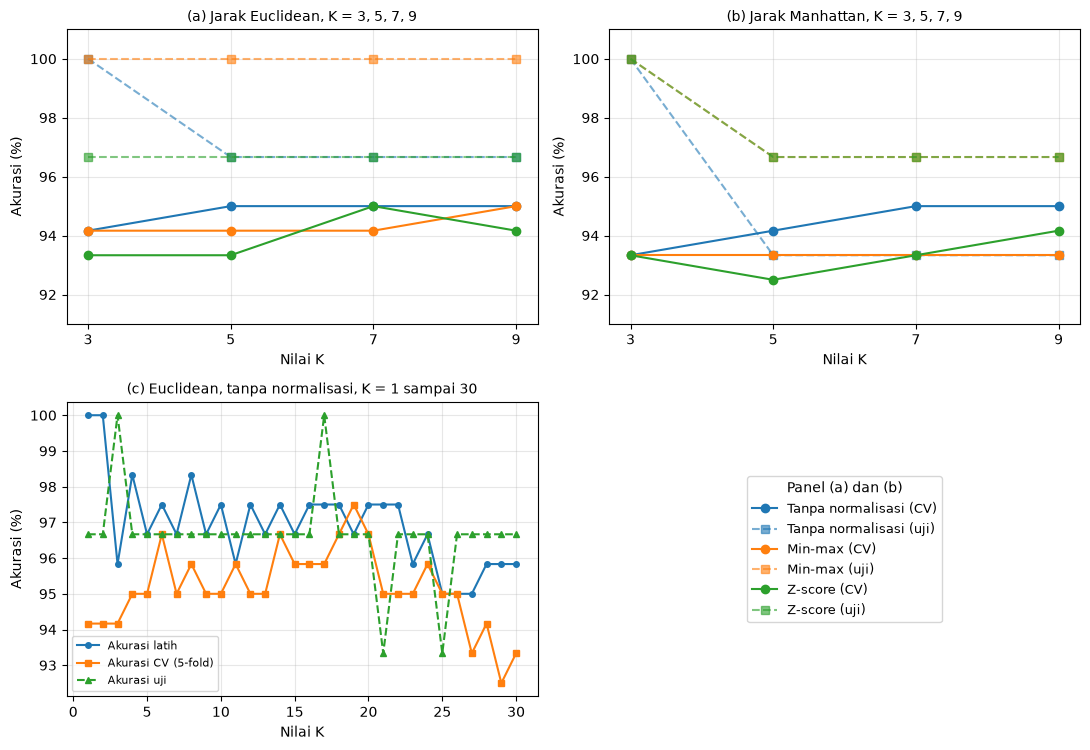

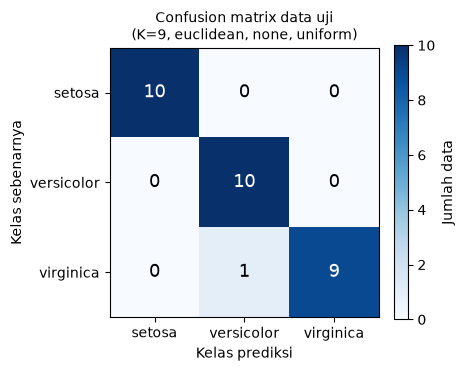

In [11]:
# --- data kurva K = 1..30 (dipakai sebagai panel (c) Gambar 1) ---
Ks = list(range(1, 31)); lat, cvv, tes = [], [], []
Xa, Xb = apply_scaler("none", X_tr, X_te)
for k in Ks:
    mdl = KNNClassifier(k=k).fit(Xa, y_tr)
    lat.append(accuracy_score(y_tr, mdl.predict(Xa))); tes.append(accuracy_score(y_te, mdl.predict(Xb)))
    cvv.append(cv_acc(k, "euclidean", "uniform", "none")[0])
RESULTS["supl"] = dict(K=Ks, latih=lat, cv=cvv, uji=tes)

# --- Gambar 1: pengaruh K terhadap akurasi (judul, label sumbu, legenda) ---
import matplotlib.gridspec as gridspec
fig = plt.figure(figsize=(11, 7.6)); gs = gridspec.GridSpec(2, 2, figure=fig)
axa, axb, axc, axl = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1], sharey=None), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])
for ax, (m, ttl) in zip((axa, axb), [("euclidean", "(a) Jarak Euclidean, K = 3, 5, 7, 9"), ("manhattan", "(b) Jarak Manhattan, K = 3, 5, 7, 9")]):
    for n, lab, c in [("none", "Tanpa normalisasi", "#1f77b4"), ("minmax", "Min-max", "#ff7f0e"), ("zscore", "Z-score", "#2ca02c")]:
        d = grid_u[(grid_u.metrik == m) & (grid_u.normalisasi == n)]
        ax.plot(d.K, d.acc_cv * 100, "o-", color=c, label=f"{lab} (CV)")
        ax.plot(d.K, d.acc_uji * 100, "s--", color=c, alpha=.6, label=f"{lab} (uji)")
    ax.set_title(ttl, fontsize=10); ax.set_xlabel("Nilai K"); ax.set_ylabel("Akurasi (%)"); ax.set_xticks([3, 5, 7, 9]); ax.set_ylim(91, 101); ax.grid(alpha=.3)
axc.plot(Ks, np.array(lat) * 100, "o-", ms=4, label="Akurasi latih"); axc.plot(Ks, np.array(cvv) * 100, "s-", ms=4, label="Akurasi CV (5-fold)")
axc.plot(Ks, np.array(tes) * 100, "^--", ms=4, label="Akurasi uji")
axc.set_xlabel("Nilai K"); axc.set_ylabel("Akurasi (%)"); axc.grid(alpha=.3); axc.legend(fontsize=8, loc="lower left")
axc.set_title("(c) Euclidean, tanpa normalisasi, K = 1 sampai 30", fontsize=10)
axl.axis("off"); h, l = axa.get_legend_handles_labels(); axl.legend(h, l, loc="center", fontsize=9, title="Panel (a) dan (b)")
fig.tight_layout(); fig.savefig(f"{OUT}/gambar1_k_vs_akurasi.png", dpi=200); plt.show()


# --- Grafik 2: confusion matrix ---
fig, ax = plt.subplots(figsize=(4.6, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3)); ax.set_yticks(range(3)); ax.set_xticklabels(nama_kelas); ax.set_yticklabels(nama_kelas)
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13)
ax.set_xlabel("Kelas prediksi"); ax.set_ylabel("Kelas sebenarnya")
ax.set_title(f"Confusion matrix data uji\n(K={int(best.K)}, {best.metrik}, {best.normalisasi}, {best.bobot})", fontsize=10)
fig.colorbar(im, ax=ax, fraction=.046, label="Jumlah data"); fig.tight_layout()
fig.savefig(f"{OUT}/gambar2_confusion_matrix.png", dpi=200); plt.show()

---
# BAGIAN D — Angka pendukung analisis
(Pembahasan lengkap ada di laporan; sel ini mencetak angka yang dirujuk.)

In [12]:
print("Rata-rata akurasi per K:\n", ring_k, "\n\nPer normalisasi:\n", ring_norm, "\n\nPer metrik:\n", ring_met, "\n\nPer bobot:\n", ring_bobot)
# selisih akurasi CV Euclidean vs Manhattan pada tiap normalisasi
sel = grid_u.pivot_table(index=["normalisasi", "K"], columns="metrik", values="acc_cv"); sel["selisih_E-M"] = sel.euclidean - sel.manhattan
print(sel.round(4))

with open(f"{OUT}/results.json", "w") as f:
    json.dump(RESULTS, f, indent=1, default=lambda o: o.tolist() if hasattr(o, "tolist") else str(o))
print("Selesai. Angka tersimpan di", f"{OUT}/results.json")

Rata-rata akurasi per K:
    acc_latih  acc_cv  acc_uji
K                            
3     0.9542  0.9361   0.9944
5     0.9569  0.9375   0.9667
7     0.9556  0.9431   0.9667
9     0.9542  0.9444   0.9667 

Per normalisasi:
              acc_cv  acc_uji
normalisasi                 
minmax       0.9385   0.9875
none         0.9458   0.9625
zscore       0.9365   0.9708 

Per metrik:
            acc_cv  acc_uji
metrik                    
euclidean  0.9438   0.9806
manhattan  0.9368   0.9667 

Per bobot:
           acc_cv  acc_uji
bobot                    
distance  0.9347   0.9875
uniform   0.9403   0.9736
metrik         euclidean  manhattan  selisih_E-M
normalisasi K                                   
minmax      3     0.9417     0.9333       0.0083
            5     0.9417     0.9333       0.0083
            7     0.9417     0.9333       0.0083
            9     0.9500     0.9333       0.0167
none        3     0.9417     0.9333       0.0083
            5     0.9500     0.9417       0.0